In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import tables as tb
import glob as glob

import time
import os

from tqdm import tqdm

In [2]:
path = glob.glob(f"/data/pablovzqz/NEXT100-data/HE/hits_parts/*.h5")

In [3]:
def load_hits(path):

    with tb.open_file(path, mode="r") as f:

        group = f.root.hits

        arrays = []
        columns = []

        i = 0
        while hasattr(group, f"block{i}_values"):

            values = getattr(group, f"block{i}_values")[:]
            items = getattr(group, f"block{i}_items")[:]

            names = [
                x.decode("utf-8") if isinstance(x, bytes) else x
                for x in items
            ]

            arrays.append(values)
            columns.extend(names)

            i += 1

        return pd.DataFrame(
            np.concatenate(arrays, axis=1),
            columns=columns
        )

dfs = []

for p in tqdm(path[0:15]):
    dfs.append(load_hits(p))

df = pd.concat(dfs, ignore_index=True)

del dfs


100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 15/15 [01:19<00:00,  5.27s/it]


In [4]:
df

,time,Xpeak,Ypeak,X,Y,Xrms,Yrms,Z,Q,E,Qc,Ec,Ep,track_id,event,npeak,nsipm
0,1.751991e+09,119.185013,108.096961,-281.475,-48.025,0.0,0.0,755.397125,7.349339,-2.372883,-1.0,-0.000012,-1.0,-1.0,15968.0,13.0,1.0
1,1.751991e+09,119.185013,108.096961,212.125,152.625,0.0,0.0,771.512375,8.328227,-6.996728,-1.0,-0.000037,-1.0,-1.0,15968.0,13.0,1.0
2,1.751991e+09,119.185013,108.096961,-65.775,369.325,0.0,0.0,776.969750,7.717801,-0.337646,-1.0,-0.000002,-1.0,-1.0,15968.0,13.0,1.0
3,1.751991e+09,119.185013,108.096961,-173.625,414.975,0.0,0.0,787.762125,7.157535,14.028790,-1.0,0.000094,-1.0,-1.0,15968.0,13.0,1.0
4,1.751991e+09,119.185013,108.096961,273.325,337.725,0.0,0.0,807.664125,10.206654,320.662196,-1.0,0.002027,-1.0,-1.0,15968.0,13.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
339788575,1.752674e+09,66.884219,93.721882,88.725,-263.225,0.0,0.0,738.687250,10.340457,729.623124,-1.0,0.003831,-1.0,-1.0,3824506.0,29.0,1.0
339788576,1.752674e+09,66.884219,93.721882,-173.625,322.675,0.0,0.0,746.608625,7.745082,192.008604,-1.0,0.001043,-1.0,-1.0,3824506.0,29.0,1.0
339788577,1.752674e+09,66.884219,93.721882,-173.625,-263.225,0.0,0.0,766.618125,7.121831,72.907933,-1.0,0.000394,-1.0,-1.0,3824506.0,29.0,1.0
339788578,1.752674e+09,66.884219,93.721882,-235.825,260.475,0.0,0.0,766.618125,7.823161,80.087622,-1.0,0.000445,-1.0,-1.0,3824506.0,29.0,1.0


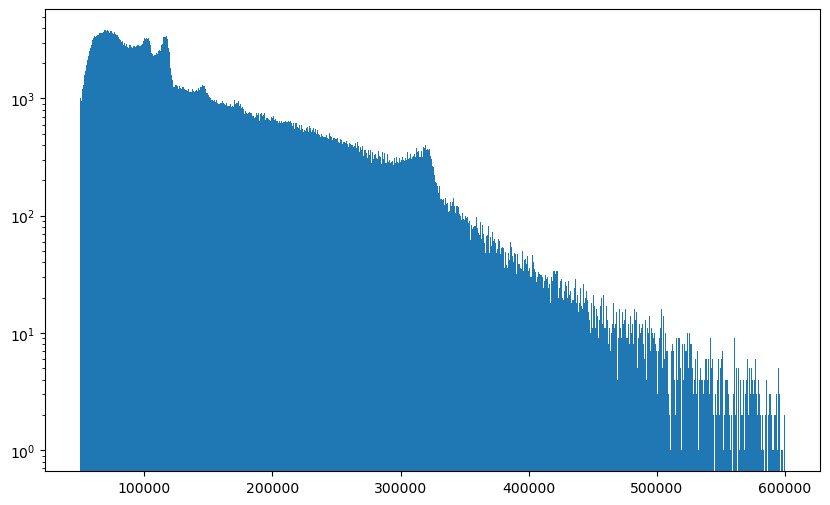

In [5]:
plt.figure(figsize=(10, 6))
plt.hist(df.groupby('event').E.agg('sum'), bins=1000, range = (0.5e5, 6e5));
plt.yscale('log')

Text(0, 0.5, 'Y [mm]')

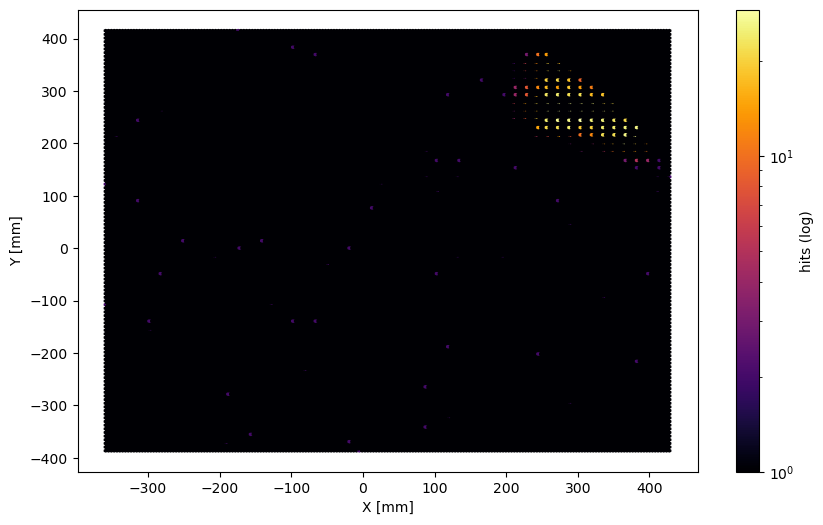

In [6]:
ev = df[df.event == df.event.iloc[300]]

plt.figure(figsize=(10, 6))
plt.hexbin(ev.X, ev.Y, gridsize=200, bins='log', cmap='inferno')
plt.colorbar(label='hits (log)')
plt.xlabel('X [mm]'); 
plt.ylabel('Y [mm]')

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import DBSCAN
from tqdm.auto import tqdm

A, B = 14.55, 3.7            # escala XY y Z [mm]
SCALE = np.array([A, A, B])
EPS, MIN_SAMPLES = 2.3, 5    # EPS en unidades escaladas
FEATS = ["X", "Y", "Z"]

def cluster_labels(xyz):
    return DBSCAN(eps=EPS, min_samples=MIN_SAMPLES).fit_predict(xyz / SCALE)

# --- agrupar por evento ---
N_EVENTS = 200000                     # para probar; quita estas dos líneas para procesar todos
sub = df[df.event.isin(df.event.unique()[:N_EVENTS])]

d = sub.sort_values("event")
ids, start, counts = np.unique(d["event"].to_numpy(), return_index=True, return_counts=True)
xyz_all = d[FEATS].to_numpy()
groups = [xyz_all[s:s + c] for s, c in zip(start, counts)]

rows = []
for eid, xyz in zip(tqdm(ids), groups):
    lab = cluster_labels(xyz)
    rows.append((eid, len(set(lab) - {-1})))     # el ruido (-1) no cuenta

clusters_df = pd.DataFrame(rows, columns=["event", "n_clusters"])
print(clusters_df.n_clusters.value_counts().sort_index())


# --- plots: 5 eventos con 1 cluster y 5 con 2 ---
def plot_events(n, n_plots=5, seed=0):
    evs = clusters_df.loc[clusters_df.n_clusters == n, "event"]
    if len(evs) == 0:
        print(f"No hay eventos con {n} cluster(s)")
        return
    evs = evs.sample(min(n_plots, len(evs)), random_state=seed).to_numpy()

    fig, axes = plt.subplots(2, len(evs), figsize=(4 * len(evs), 7), squeeze=False)
    for j, eid in enumerate(evs):
        xyz = d.loc[d.event == eid, FEATS].to_numpy()
        lab = cluster_labels(xyz)

        for l in np.unique(lab):
            m = lab == l
            kw = dict(c="lightgray", marker="x", s=10) if l == -1 else dict(color=f"C{l}", s=10)
            axes[0, j].scatter(xyz[m, 0], xyz[m, 1], **kw)   # XY
            axes[1, j].scatter(xyz[m, 0], xyz[m, 2], **kw)   # XZ

        axes[0, j].set_title(f"evento {eid}")
        axes[0, j].set_xlabel("X [mm]"); axes[0, j].set_ylabel("Y [mm]")
        axes[1, j].set_xlabel("X [mm]"); axes[1, j].set_ylabel("Z [mm]")

    fig.suptitle(f"{n} cluster(s)  (gris = ruido)")
    plt.tight_layout()
    plt.show()

plot_events(1)
plot_events(2)

  0%|          | 0/200000 [00:00<?, ?it/s]

In [ ]:
clusters_df[clusters_df.n_clusters == 2].head(10)

,event,n_clusters
0,23.0,2
1,54.0,2
3,76.0,2
19,378.0,2
20,387.0,2
22,433.0,2
23,442.0,2
26,463.0,2
29,523.0,2
36,667.0,2


In [ ]:
df = df[df.event.isin(clusters_df.loc[clusters_df.n_clusters == 2, "event"])]